# TP3 — Modelos clásicos (reconstruido)

Este notebook **reconstruye el código** del experimento clásico documentado en la conversación; **no recupera las celdas originales** del archivo dañado.

**Orden:** ejecutar las celdas de arriba hacia abajo. Se utilizan los CSV compartidos dentro de `TP IA y Neuro/data/`.

**Protocolo:** elegir configuración usando **validación**; evaluar en **test solo al final** y no retocar hiperparámetros mirando test.

In [6]:
import pandas as pd
import time
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

# Si tenés un acceso directo en otro lugar de Drive, modificá solo esta ruta.
RAIZ = Path('/content/drive/MyDrive/TP IA y Neuro')
DATOS = RAIZ / 'data'
RESULTADOS = RAIZ / 'resultados'

assert DATOS.is_dir(), f'No encontré la carpeta {DATOS}. Revisá la ruta.'
RESULTADOS.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATOS / 'train.csv')
val = pd.read_csv(DATOS / 'val.csv')
test = pd.read_csv(DATOS / 'test.csv')

print('Datos cargados:', len(train), len(val), len(test))
print('Columnas disponibles:', train.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Datos cargados: 2100 450 450
Columnas disponibles: ['id', 'target', 'description', 'comment', 'annotation_1', 'annotation_2', 'annotation_3', 'majority_label', 'text']


In [7]:
clases = ['favor', 'against', 'neutral']

def preparar(df):
    df = df.copy()
    df['majority_label'] = df['majority_label'].astype('string').str.strip().str.lower()
    df = df[df['majority_label'].isin(clases)].copy()
    df['text'] = df['text'].fillna('').astype(str)
    return df

train = preparar(train)
val = preparar(val)
test = preparar(test)

assert set(train['majority_label'].unique()) == set(clases), 'Faltan clases en entrenamiento'
assert set(val['majority_label'].unique()) == set(clases), 'Faltan clases en validación'
print('Training:', len(train), 'Validation:', len(val), 'Test:', len(test))

Training: 1995 Validation: 428 Test: 427


## 1. Reproducir los experimentos clásicos en validación

Se entrenan las **mismas cinco configuraciones** utilizadas anteriormente. El mejor modelo seleccionado previamente fue `TF-IDF + Bigramas`, con Macro-F1 de validación aproximadamente **0.4914** (puede variar levemente según versiones del entorno).

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

modelos = {
    'Dummy (referencia)': make_pipeline(
        TfidfVectorizer(),
        DummyClassifier(strategy='most_frequent')
    ),
    'TF-IDF + Logistic Regression': make_pipeline(
        TfidfVectorizer(),
        LogisticRegression(max_iter=1000)
    ),
    'TF-IDF + Bigramas': make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight='balanced')
    ),
    'TF-IDF + SVM': make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LinearSVC(class_weight='balanced')
    ),
    'TF-IDF caracteres + SVM': make_pipeline(
        TfidfVectorizer(analyzer='char', ngram_range=(3, 5)),
        LinearSVC(class_weight='balanced')
    ),
}

resultados = []
modelos_entrenados = {}
for nombre, modelo in modelos.items():
    inicio = time.perf_counter()
    modelo.fit(train['text'], train['majority_label'])
    tiempo_train = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred = modelo.predict(val['text'])
    tiempo_inferencia = time.perf_counter() - inicio

    f1 = f1_score(val['majority_label'], pred, labels=clases,
                  average='macro', zero_division=0)
    resultados.append({
        'Modelo': nombre,
        'Macro-F1': f1,
        'Entrenamiento (s)': tiempo_train,
        'Inferencia (s)': tiempo_inferencia,
    })
    modelos_entrenados[nombre] = modelo

resultados_df = pd.DataFrame(resultados)
display(resultados_df.sort_values('Macro-F1', ascending=False))
resultados_df.to_csv(RESULTADOS / 'modelos_clasicos.csv', index=False)
print('Validación guardada en resultados/modelos_clasicos.csv')

,Modelo,Macro-F1,Entrenamiento (s),Inferencia (s)
2,TF-IDF + Bigramas,0.491436,4.012954,0.162423
3,TF-IDF + SVM,0.481819,0.859838,0.086777
4,TF-IDF caracteres + SVM,0.454256,3.855502,0.385051
1,TF-IDF + Logistic Regression,0.315303,0.984077,0.103003
0,Dummy (referencia),0.256115,0.161837,0.027183


Validación guardada en resultados/modelos_clasicos.csv


              precision    recall  f1-score   support

       favor       0.73      0.77      0.75       267
     against       0.48      0.55      0.51        94
     neutral       0.30      0.16      0.21        67

    accuracy                           0.63       428
   macro avg       0.50      0.50      0.49       428
weighted avg       0.61      0.63      0.61       428



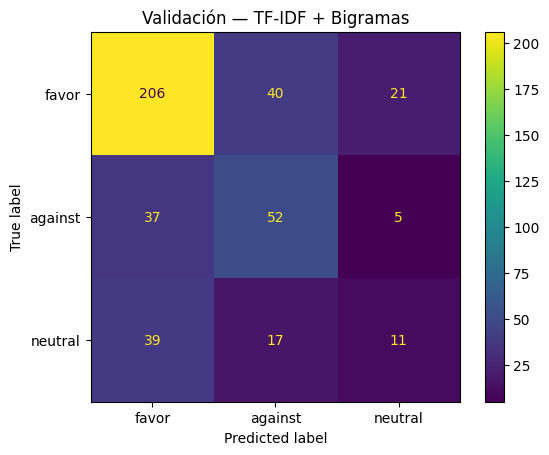

In [9]:
import matplotlib.pyplot as plt

nombre = 'TF-IDF + Bigramas'  # Elegido ANTES de observar test.
modelo_final = modelos_entrenados[nombre]
pred_val = modelo_final.predict(val['text'])
print(classification_report(val['majority_label'], pred_val,
                            labels=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(val['majority_label'], pred_val, labels=clases)
plt.title('Validación — TF-IDF + Bigramas')
plt.show()

## 2. Evaluación final sobre test

**Ejecutar solo después de confirmar la selección del modelo por validación**. No ajustar el modelo después de revisar el resultado de test.

In [10]:
# Evaluación final: usa el modelo entrenado en TRAIN, sin reentrenarlo sobre TEST.
inicio = time.perf_counter()
pred_test = modelo_final.predict(test['text'])
tiempo_test = time.perf_counter() - inicio
f1_test = f1_score(test['majority_label'], pred_test, labels=clases,
                   average='macro', zero_division=0)

print('Macro-F1 TEST:', round(f1_test, 4))
print('Inferencia TEST (s):', round(tiempo_test, 4))
print(classification_report(test['majority_label'], pred_test,
                            labels=clases, zero_division=0))

# No asumimos que existe la columna «id»: puede no estar presente en el CSV.
cols = ['id'] if 'id' in test.columns else []
predicciones_test = test[cols + ['majority_label']].copy()
predicciones_test['prediccion'] = pred_test
predicciones_test.to_csv(RESULTADOS / 'test_clasico.csv', index=False)

resumen_test = pd.DataFrame([{
    'Modelo': nombre,
    'Macro-F1 Test': f1_test,
    'Inferencia Test (s)': tiempo_test,
    'N Test': len(test)
}])
resumen_test.to_csv(RESULTADOS / 'resumen_test_clasico.csv', index=False)
print('Resultados TEST guardados en la carpeta resultados.')

Macro-F1 TEST: 0.535
Inferencia TEST (s): 0.073
              precision    recall  f1-score   support

       favor       0.74      0.78      0.76       267
     against       0.48      0.51      0.50        94
     neutral       0.42      0.30      0.35        66

    accuracy                           0.64       427
   macro avg       0.55      0.53      0.54       427
weighted avg       0.63      0.64      0.64       427

Resultados TEST guardados en la carpeta resultados.
